# **Diffusion Models: Foundations and the Forward Process**

This notebook builds the probabilistic picture behind denoising diffusion models (DDMs), then implements the forward noising process in PyTorch. It also introduces the Flowers102 data used in the later notebooks.

**Learning goals**
- Explain a generative model as a way to transform a simple distribution into a data distribution.
- Derive the closed-form forward marginal $q(x_t\mid x_0)$.
- Inspect how signal and Gaussian noise change an image over time.
- Connect the Markov-chain view to the one-step sampling formula used in code.

The notebook series follows this path: forward process → schedules and reverse process → U-Net, training, sampling, and analysis. The implementation is intentionally a small educational DDPM, not a production text-to-image system.

## 1. Generative modeling viewpoint

Let real images follow an unknown distribution $p_{\mathrm{data}}(x)$. A generative model defines a tractable procedure for drawing samples whose distribution resembles $p_{\mathrm{data}}$. Diffusion models start from a simple Gaussian $x_T\sim\mathcal N(0,I)$ and learn a sequence of denoising transitions that gradually recover structure.

A useful mental model is controlled corruption and its learned undoing. The forward direction is fixed and easy to sample; learning is concentrated in the reverse direction. The intermediate states need not look like valid images: they are coordinates along a gradual change from data to noise.

In [1]:
import math
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

SEED = 42
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch: {torch.__version__} | device: {device}')

PyTorch: 2.4.1+cpu | device: cpu


## 2. Flowers102: the running image dataset

Flowers102 contains 102 flower categories. For the diffusion examples we use its training split and resize images to a common square resolution. The original labels are not used by the unconditional model: it learns the image distribution without being told the category. Later, the labels still help us inspect sample variety.

> **Download note:** `Flowers102(download=True)` fetches the dataset the first time. If automatic downloads are unavailable, download Flowers102 with torchvision's documented layout or replace the dataset cell with an `ImageFolder` pointed at your own flower directory.

We map RGB pixels to $[-1,1]$. This symmetric range is convenient because the final network predicts a noise residual with values centered near zero.

In [2]:
IMAGE_SIZE = 64
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
flowers = datasets.Flowers102(root='data/flowers102', split='train', download=True, transform=transform)
print('Training examples:', len(flowers))
print('Image shape:', flowers[0][0].shape, '| label:', flowers[0][1])

100%|██████████| 344862509/344862509 [01:33<00:00, 3674547.99it/s] 


Extracting data\flowers102\flowers-102\102flowers.tgz to data\flowers102\flowers-102


100%|██████████| 502/502 [00:00<?, ?it/s]


100%|██████████| 14989/14989 [00:00<00:00, 16850287.50it/s]


Training examples: 1020
Image shape: torch.Size([3, 64, 64]) | label: 0


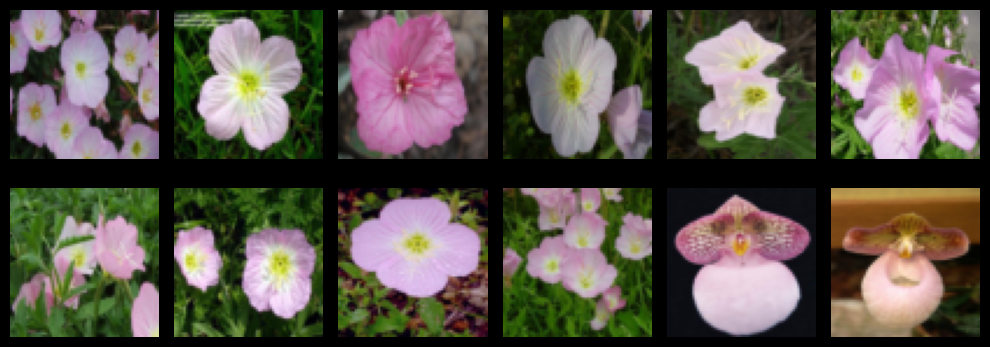

In [3]:
def show_image_grid(images, titles=None, columns=6, value_range=(-1, 1), figsize=None):
    images = images.detach().cpu()
    n = len(images)
    rows = math.ceil(n / columns)
    fig, axes = plt.subplots(rows, columns, figsize=figsize or (2 * columns, 2 * rows), squeeze=False)
    lo, hi = value_range
    for i, ax in enumerate(axes.flat):
        ax.axis('off')
        if i < n:
            img = images[i].permute(1, 2, 0).clamp(lo, hi)
            ax.imshow((img - lo) / (hi - lo))
            if titles is not None: ax.set_title(str(titles[i]))
    plt.tight_layout()
    return fig

preview = torch.stack([flowers[i][0] for i in range(12)])
show_image_grid(preview, columns=6, figsize=(10, 4));

## 3. The forward diffusion process

We define a Markov chain that adds a small amount of isotropic Gaussian noise at each step. For $t=1,\ldots,T$,

$$q(x_t\mid x_{t-1})=\mathcal N\!\left(x_t;\sqrt{1-\beta_t}x_{t-1},\,\beta_t I\right),$$

where $\beta_t\in(0,1)$ is the variance of the new noise. Write $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^t\alpha_s$. Repeated substitution gives the important closed form

$$q(x_t\mid x_0)=\mathcal N\!\left(\sqrt{\bar\alpha_t}x_0,\,(1-\bar\alpha_t)I\right), \qquad x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\quad\epsilon\sim\mathcal N(0,I).$$

The derivation uses closure of Gaussians under affine transformations and addition. If $x_{t-1}$ contains signal coefficient $\sqrt{\bar\alpha_{t-1}}$, multiplying by $\sqrt{\alpha_t}$ yields $\sqrt{\bar\alpha_t}$. The independent noise variances combine to $\alpha_t(1-\bar\alpha_{t-1})+\beta_t=1-\bar\alpha_t$.

This lets us jump directly from $x_0$ to any $x_t$ in one operation; simulating all preceding steps is unnecessary during training.

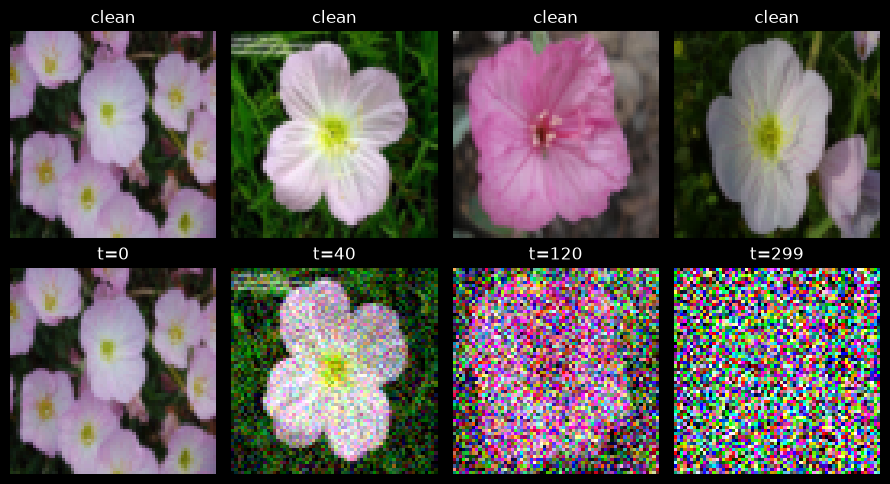

In [4]:
T = 300
betas = torch.linspace(1e-4, 0.02, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

def extract(values, timesteps, x_shape):
    """Gather one schedule value per batch item and reshape for broadcasting."""
    out = values.gather(0, timesteps)
    return out.view(timesteps.shape[0], *([1] * (len(x_shape) - 1)))

def q_sample(x0, t, noise=None):
    """Sample x_t directly from q(x_t | x_0), for integer t in [0, T-1]."""
    if noise is None: noise = torch.randn_like(x0)
    a_bar = extract(alpha_bars, t, x0.shape)
    return a_bar.sqrt() * x0 + (1.0 - a_bar).sqrt() * noise

x0 = preview[:4].to(device)
chosen_t = torch.tensor([0, 40, 120, T - 1], device=device)
xt = q_sample(x0, chosen_t)
show_image_grid(torch.cat([x0.cpu(), xt.cpu()]), titles=['clean'] * 4 + [f't={t}' for t in chosen_t.tolist()], columns=4, figsize=(9, 5));

## 4. Signal-to-noise intuition

At time $t$, the signal amplitude is $\sqrt{\bar\alpha_t}$ and the noise amplitude is $\sqrt{1-\bar\alpha_t}$. Their squared ratio is the signal-to-noise ratio (SNR):

$$\mathrm{SNR}(t)=\frac{\bar\alpha_t}{1-\bar\alpha_t}.$$

Early in the chain, $\bar\alpha_t\approx1$: images are recognizable and noise is weak. Late in the chain, $\bar\alpha_t\approx0$: almost all image-specific information has been removed. This information destruction is deliberate: it gives the model a simple, known terminal distribution to start sampling from.

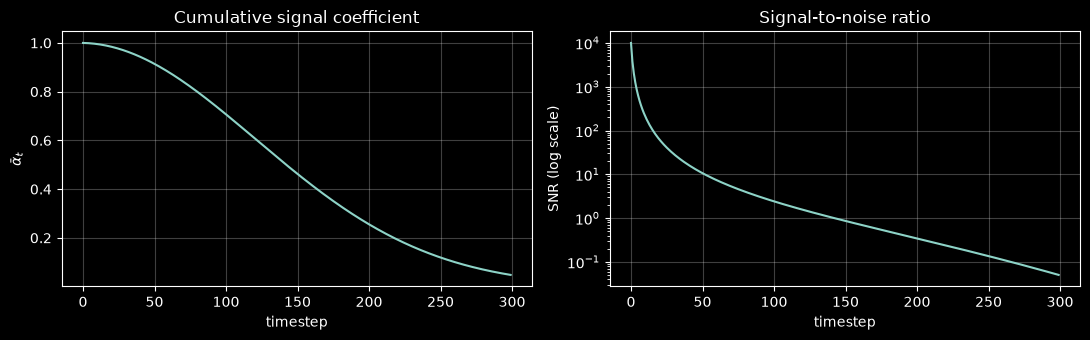

In [5]:
snr = alpha_bars / (1 - alpha_bars)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(alpha_bars.cpu()); axes[0].set(title='Cumulative signal coefficient', xlabel='timestep', ylabel=r'$\bar{\alpha}_t$')
axes[1].semilogy(snr.cpu()); axes[1].set(title='Signal-to-noise ratio', xlabel='timestep', ylabel='SNR (log scale)')
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout();

## 5. What the forward process does—and does not do

The forward chain is a *corruption process*, not a learned image transformation. Each conditional distribution is known analytically, so no neural network is needed to produce noisy examples. The model later learns to estimate the noise present at a randomly selected level.

A common conceptual trap is to think that the network reconstructs the original image from a single noisy input. It cannot recover information that is irretrievably absent. Instead, it learns statistical structure from the entire training set: given a noisy image and its noise level, it predicts a plausible noise residual (equivalently, a direction toward regions of higher data likelihood). This is why samples are plausible but not exact copies of any training image.

## Summary

- The forward chain gradually scales down image signal and injects independent Gaussian noise.
- Its marginal has a closed form, $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$.
- The schedule controls *when* information is destroyed; `alpha_bars` describes cumulative signal retention.
- Notebook 02 develops schedule choices, the reverse transition, and the noise-prediction objective.